# Figure 6 Benchmark

This notebook reproduces the benchmark results presented in Figure 6.

* [Part 1: Domain/Niche Detection Accuracy](#1-domainniche-detection-accuracy)

  * [1.1 Calculate ARI and NMI](#11-calculate-ari-and-nmi)
  * [1.2 Illustration Using the STARmap Mouse Brain Well05 Dataset](#12-illustration-using-the-starmap-mouse-brain-well05-dataset)
  * [1.3 Plot Benchmark Results](#13-plot-benchmark-results)
* [Part 2: Runtime and Memory Usage](#2-runtime-and-memory-usage)

## 1. Domain/Niche Detection Accuracy

### 1.1 Calculate ARI and NMI

This section evaluates clustering performance against the annotated spatial domains or niches using the Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).

Clustering results are loaded from `./Figure6_methods_raw_outputs`, and the calculated evaluation metrics are saved to `./Outputs`.

In [1]:
# Set plotting parameters
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

from IPython.display import display
from matplotlib import rcParams
import matplotlib as mpl  

config = {
    "font.family":'sans-serif',
    "font.size": 6,
    "mathtext.fontset":'stix',
    "font.serif": ['MS Arial'],
}
rcParams.update(config)

import matplotlib as mpl
import seaborn as sns

sns.set_context("talk", font_scale=1.1)           
mpl.rcParams.update({
    "font.size": 6,         
    "axes.titlesize": 6,     
    "axes.labelsize": 6,     
    "xtick.labelsize": 6,     
    "ytick.labelsize": 6,     
    "legend.fontsize": 6,     
})

sns.set_context("paper", font_scale=1.0)  
mpl.rcParams.update({
    "axes.linewidth": 0.6,     
    "grid.linewidth": 0.4,     
    "grid.alpha": 0.5,         
    "xtick.major.width": 0.5,  
    "ytick.major.width": 0.5,
    "lines.linewidth": 0.8,    
})

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42



#### Benchmark Parameter Settings

Default or author-recommended parameter settings from the official implementations or publications were used for all methods, except for clustering resolution and scale-related parameters.

* **Clustering resolution:** For each method, clustering was performed across a range of resolutions. The evaluation pipeline automatically selected the result with a cluster number comparable across methods.

* **BANKSY:** BANKSY operates at two scales, corresponding to the single-cell and domain scales, and its ARI/NMI was evaluated at the domain scale.

* **SpatialZoomer:** SpatialZoomer generates multi-scale clustering results in a single run, and only one or a few scales are expected to correspond to niche/domain structures. Therefore, we reported the average ARI/NMI of SpatialZoomer across **a broad range of the scale parameter from 5.0 to 10.0** in the comparison.


In [2]:
from pathlib import Path

result_dir = Path("./Data/")
TRUE_LABEL_DIR = result_dir / 'Figure6_true_labels'
RAW_RESULT_DIR = result_dir / 'Figure6_methods_raw_outputs'

METHODS = [
    "spatialzoomer",
    "mender",
    "cellcharter",
    "banksy",
    "stagate",
]
NON_SPATIALZOOMER_METHODS = [method for method in METHODS if method != 'spatialzoomer']
DEFAULT_SCALE_RANGE = (5.0, 10.0)

datasets = [
    'cosmx_Lung12',
    'cosmx_Lung13',
    'cosmx_Lung5_Rep1',
    'cosmx_Lung5_Rep2',
    'cosmx_Lung5_Rep3',
    'cosmx_Lung6',
    'cosmx_Lung9_Rep1',
    'cosmx_Lung9_Rep2',
    'cosmx_mousebrain',
    'starmap_mousebrain_well05',
    'starmap_mousebrain_well06',
    'starmap_mousebrain_well11',
    'xenium_mousebrain'
    ]

HIGHLIGHT_DATASET = 'starmap_mousebrain_well05'

In [3]:
from functools import lru_cache
import re
import numpy as np
import pandas as pd
import sklearn.metrics

SCALE_PATTERN = re.compile(r'leiden_scale(?P<scale>[0-9.]+)_res(?P<res>[0-9.]+)')
n_cluster_df = pd.read_csv(result_dir/ 'Figure6_benchmark_cluster_number.csv')
custom_target_n_map = dict(zip(n_cluster_df['dataset_name'], n_cluster_df['cluster_number']))


def calculate_ari(labels_pred, labels_true):
    return sklearn.metrics.adjusted_rand_score(labels_true, labels_pred)


def calculate_nmi(labels_pred, labels_true):
    return sklearn.metrics.normalized_mutual_info_score(
        labels_true,
        labels_pred,
        average_method='arithmetic',
    )


@lru_cache(maxsize=None)
def load_true_labels(dataset):
    labels = pd.read_csv(TRUE_LABEL_DIR / f'{dataset}.csv', index_col=0).iloc[:, 0]
    labels.name = 'true_label'
    return labels


@lru_cache(maxsize=None)
def load_predictions(dataset, method):
    file_path = RAW_RESULT_DIR / f"{dataset}_{method}.csv"
    if not file_path.exists():
        raise FileNotFoundError(f"Merged file not found: {file_path}")
    return pd.read_csv(file_path, index_col=0)


def align_and_filter(dataset, pred):
    true_labels = load_true_labels(dataset)
    common_idx = true_labels.index.intersection(pred.index)

    if len(common_idx) == 0:
        true_labels = true_labels.copy()
        pred = pred.copy()
        true_labels.index = true_labels.index.astype(str)
        pred.index = pred.index.astype(str)
        common_idx = true_labels.index.intersection(pred.index)

    true_labels = true_labels.loc[common_idx]
    pred = pred.loc[common_idx]
    valid_mask = ~true_labels.isna()
    return true_labels.loc[valid_mask].astype(str), pred.loc[valid_mask]


def parse_spatialzoomer_columns(pred):
    rows = []
    for column in pred.columns:
        match = SCALE_PATTERN.fullmatch(column)
        if match:
            rows.append({
                'column': column,
                'scale': float(match.group('scale')),
                'resolution': float(match.group('res')),
                'n_clusters': int(pred[column].astype(str).nunique()),
            })
    return pd.DataFrame(rows)


def selected_column(selected_col_df, dataset, method):
    if dataset not in selected_col_df.index or method not in selected_col_df.columns:
        return None
    value = selected_col_df.loc[dataset, method]
    return None if pd.isna(value) else str(value)


def select_spatialzoomer_columns(dataset, target_n, scale_min, scale_max):
    pred = load_predictions(dataset, 'spatialzoomer')
    _, pred = align_and_filter(dataset, pred)
    meta = parse_spatialzoomer_columns(pred)
    meta = meta[(meta['scale'] > scale_min) & (meta['scale'] < scale_max)].copy()
    if meta.empty:
        raise ValueError(f'No SpatialZoomer columns found for {dataset} with {scale_min} < scale < {scale_max}.')

    selected_rows = []
    for scale, group in meta.groupby('scale', sort=True):
        chosen = group.iloc[(group['n_clusters'] - target_n).abs().argmin()].copy()
        chosen['target_n'] = int(target_n)
        selected_rows.append(chosen)
    return pd.DataFrame(selected_rows).reset_index(drop=True)


def method_cluster_counts(dataset, selected_col_df):
    counts = {}
    for method in NON_SPATIALZOOMER_METHODS:
        column = selected_column(selected_col_df, dataset, method)
        if column is None:
            continue
        try:
            pred = load_predictions(dataset, method)
            _, pred = align_and_filter(dataset, pred)
        except FileNotFoundError:
            continue
        if column in pred.columns:
            counts[method] = int(pred[column].astype(str).nunique())
    return counts


def select_closest_column_by_cluster_count(dataset, method, target_n):
    """Select the column whose cluster count is closest to target_n."""
    pred = load_predictions(dataset, method)
    _, pred = align_and_filter(dataset, pred)

    if method == 'spatialzoomer':
        candidate_df = parse_spatialzoomer_columns(pred)
        if candidate_df.empty:
            raise ValueError(f'No SpatialZoomer columns found for {dataset}.')
    else:
        candidate_df = pd.DataFrame({
            'column': pred.columns,
            'n_clusters': [int(pred[column].astype(str).nunique()) for column in pred.columns],
        })
        if candidate_df.empty:
            raise ValueError(f'No prediction columns found for {dataset} and {method}.')

    candidate_df = candidate_df.copy()
    candidate_df['cluster_count_diff'] = (candidate_df['n_clusters'] - target_n).abs()
    chosen = candidate_df.sort_values(
        by=['cluster_count_diff', 'n_clusters'],
        ascending=[True, False],
        kind='mergesort'
    ).iloc[0]
    return str(chosen['column']), int(chosen['n_clusters'])


def select_spatialzoomer_columns_for_range(dataset, target_n, scale_min, scale_max):
    """Select one SpatialZoomer column per scale within the requested range."""
    pred = load_predictions(dataset, 'spatialzoomer')
    _, pred = align_and_filter(dataset, pred)
    meta = parse_spatialzoomer_columns(pred)
    meta = meta[(meta['scale'] > scale_min) & (meta['scale'] < scale_max)].copy()
    if meta.empty:
        raise ValueError(f'No SpatialZoomer columns found for {dataset} with {scale_min} < scale < {scale_max}.')

    selected_rows = []
    for scale, group in meta.groupby('scale', sort=True):
        chosen = group.iloc[(group['n_clusters'] - target_n).abs().argmin()].copy()
        selected_rows.append(chosen)
    return pd.DataFrame(selected_rows).reset_index(drop=True)


def evaluate_spatialzoomer(dataset):
    """Evaluate SpatialZoomer using the columns selected in the custom sweep and average NMI/ARI over them."""
    pred = load_predictions(dataset, 'spatialzoomer')
    true_labels, pred = align_and_filter(dataset, pred)

    target_n = custom_target_n_map[dataset]
    selected = select_spatialzoomer_columns_for_range(
        dataset,
        target_n,
        DEFAULT_SCALE_RANGE[0],
        DEFAULT_SCALE_RANGE[1],
    )

    if selected.empty:
        raise ValueError(f'No SpatialZoomer columns were selected for {dataset}.')

    metric_rows = []
    for _, row in selected.iterrows():
        column_name = row['column']
        labels_pred = pred[column_name].astype(str).values
        labels_true = true_labels.values
        metric_rows.append({
            'dataset': dataset,
            'method': 'spatialzoomer',
            'scale': row['scale'],
            'column': column_name,
            'n_clusters': int(row['n_clusters']),
            'nmi': calculate_nmi(labels_pred, labels_true),
            'ari': calculate_ari(labels_pred, labels_true),
        })

    scale_metrics = pd.DataFrame(metric_rows)
    # The dataset-level SpatialZoomer score is the mean across the selected scales.
    averaged = {
        'dataset': dataset,
        'method': 'spatialzoomer',
        'nmi': float(scale_metrics['nmi'].mean()),
        'ari': float(scale_metrics['ari'].mean()),
        'n_clusters': ';'.join(scale_metrics['n_clusters'].astype(str).tolist()),#int(round(scale_metrics['n_clusters'].mean())),
        'selected_columns': ';'.join(scale_metrics['column'].tolist()),
    }
    return averaged, scale_metrics


def resolve_selected_column(selected_col_df, dataset, method):
    """Resolve the selected column for a dataset-method pair without relying on the shadowed helper name."""
    if dataset not in selected_col_df.index or method not in selected_col_df.columns:
        return None
    value = selected_col_df.loc[dataset, method]
    return None if pd.isna(value) else str(value)


def evaluate_method(dataset, method):
    """Evaluate a non-SpatialZoomer method by selecting the column whose
    cluster number is closest to target_n."""
    try:
        target_n = custom_target_n_map[dataset]

        column, _ = select_closest_column_by_cluster_count(
            dataset,
            method,
            target_n,
        )

        pred = load_predictions(dataset, method)
        true_labels, pred = align_and_filter(dataset, pred)

    except FileNotFoundError:
        return None

    if column not in pred.columns:
        return None

    labels_pred = pred[column].astype(str).values
    labels_true = true_labels.values

    return {
        "dataset": dataset,
        "method": method,
        "nmi": calculate_nmi(labels_pred, labels_true),
        "ari": calculate_ari(labels_pred, labels_true),
        "n_clusters": int(pd.Series(labels_pred).nunique()),
        "selected_columns": column,
    }


In [4]:
metric_records = []
spatialzoomer_scale_metric_frames = []

for dataset in datasets:
    spatialzoomer_avg, spatialzoomer_scale_metrics = evaluate_spatialzoomer(dataset)
    metric_records.append(spatialzoomer_avg)
    spatialzoomer_scale_metric_frames.append(spatialzoomer_scale_metrics)

    for method in NON_SPATIALZOOMER_METHODS:
        result = evaluate_method(dataset, method)
        if result is not None:
            metric_records.append(result)

metrics_long = pd.DataFrame(metric_records)
method_mapping = {
    'spatialzoomer': 'SpatialZoomer',
    'mender': 'MENDER',
    'cellcharter': 'CellCharter',
    'banksy': 'BANKSY',
    'stagate': 'STAGATE',
}
metrics_long['method'] = metrics_long['method'].replace(method_mapping)
DISPLAY_METHODS = [method_mapping[method] for method in METHODS]
spatialzoomer_scale_metrics = pd.concat(spatialzoomer_scale_metric_frames, ignore_index=True)

nmi_table = metrics_long.pivot(index='dataset', columns='method', values='nmi')
ari_table = metrics_long.pivot(index='dataset', columns='method', values='ari')
n_cluster_table = metrics_long.pivot(index='dataset', columns='method', values='n_clusters')
parameter_table = metrics_long.pivot(index='dataset', columns='method', values='selected_columns')

ari_df = ari_table.reindex(columns=DISPLAY_METHODS).sort_index()
nmi_df = nmi_table.reindex(columns=DISPLAY_METHODS).sort_index()

brain_mask = ari_df.index.str.contains("brain", case=False, na=False)
lung_mask = ari_df.index.str.contains("lung", case=False, na=False)

outputs = {
    "Brain_ARI.csv": ari_df.loc[brain_mask],
    "Brain_NMI.csv": nmi_df.loc[brain_mask],
    "Lung_ARI.csv": ari_df.loc[lung_mask],
    "Lung_NMI.csv": nmi_df.loc[lung_mask],
}

for filename, out_df in outputs.items():
    out_path = Path("./Outputs") / filename
    out_path.parent.mkdir(parents=True, exist_ok=True)
    out_df.to_csv(out_path)
    print(f"Saved: {out_path}")


Saved: Outputs\Brain_ARI.csv
Saved: Outputs\Brain_NMI.csv
Saved: Outputs\Lung_ARI.csv
Saved: Outputs\Lung_NMI.csv


In [5]:
def highlight_dataset_row(row):
    """Highlight the reference dataset row when rendering summary tables."""
    weight = 'font-weight: bold' if row.name == HIGHLIGHT_DATASET else ''
    return [weight] * len(row)


fig6a_nmi_table = nmi_table.copy()
fig6b_ari_table = ari_table.copy()
well05_fig6_numbers = pd.DataFrame({
    'Fig. 6a NMI': fig6a_nmi_table.loc[HIGHLIGHT_DATASET],
    'Fig. 6b ARI': fig6b_ari_table.loc[HIGHLIGHT_DATASET],
})


print('Fig. 6a NMI table')
display(fig6a_nmi_table.style.apply(highlight_dataset_row, axis=1).format('{:.4f}', na_rep=''))

print('Fig. 6b ARI table')
display(fig6b_ari_table.style.apply(highlight_dataset_row, axis=1).format('{:.4f}', na_rep=''))

Fig. 6a NMI table


method,BANKSY,CellCharter,MENDER,STAGATE,SpatialZoomer
dataset,,,,,
cosmx_Lung12,0.1688,0.2872,,,0.2788
cosmx_Lung13,0.1408,0.1855,,,0.2199
cosmx_Lung5_Rep1,0.2848,0.4778,,,0.4589
cosmx_Lung5_Rep2,0.2585,0.4746,,,0.4667
cosmx_Lung5_Rep3,0.2724,0.4428,,,0.3852
cosmx_Lung6,0.2537,0.2742,,,0.1895
cosmx_Lung9_Rep1,0.3157,0.4176,,,0.4224
cosmx_Lung9_Rep2,0.2066,0.2633,,,0.2706
cosmx_mousebrain,0.4537,0.6695,0.5763,0.3247,0.6388


Fig. 6b ARI table


method,BANKSY,CellCharter,MENDER,STAGATE,SpatialZoomer
dataset,,,,,
cosmx_Lung12,0.1119,0.1495,,,0.1949
cosmx_Lung13,0.0505,0.0749,,,0.1590
cosmx_Lung5_Rep1,0.2009,0.3200,,,0.3914
cosmx_Lung5_Rep2,0.2202,0.3364,,,0.4206
cosmx_Lung5_Rep3,0.1877,0.2821,,,0.2542
cosmx_Lung6,0.1891,0.0952,,,0.0537
cosmx_Lung9_Rep1,0.1450,0.2067,,,0.2894
cosmx_Lung9_Rep2,0.0614,0.0763,,,0.1472
cosmx_mousebrain,0.3071,0.4637,0.3782,0.2040,0.4371


### 1.2 Illustration Using the STARmap Mouse Brain Well05 Dataset

Using the `starmap_mousebrain_well05` dataset as an example, we show how the ARI and NMI scores of SpatialZoomer vary across different scales. For all datasets in this benchmark, the final SpatialZoomer performance is calculated by averaging the ARI and NMI scores obtained within the scale range $5.0 < \mathrm{scale} < 10.0$.


In [6]:
from IPython.display import display
import pandas as pd

sz_rows = spatialzoomer_scale_metrics.loc[
    spatialzoomer_scale_metrics["dataset"] == HIGHLIGHT_DATASET,
    ["scale", "nmi", "ari"]
].sort_values("scale").rename(columns={"scale": "Scale", "nmi": "NMI", "ari": "ARI"})

sz_rows.insert(0, "Method", "SpatialZoomer")
sz_rows["Scale"] = sz_rows["Scale"].map(lambda x: f"{x:.1f}")

sz_mean = pd.DataFrame({
    "Method": ["SpatialZoomer"],
    "Scale": ["Mean (5.0-10.0)"],
    "NMI": [sz_rows["NMI"].mean()],
    "ARI": [sz_rows["ARI"].mean()],
})

methods = nmi_table.columns.intersection(ari_table.columns)
other_methods = [m for m in methods if m.lower() != "spatialzoomer"]

other_rows = pd.DataFrame({
    "Method": other_methods,
    "Scale": ["—"] * len(other_methods),
    "NMI": nmi_table.loc[HIGHLIGHT_DATASET, other_methods].values,
    "ARI": ari_table.loc[HIGHLIGHT_DATASET, other_methods].values,
})

well05_results = pd.concat([sz_rows, sz_mean, other_rows], ignore_index=True)

print("STARmap mouse brain well05 benchmark results:")
display(well05_results.style.format({"NMI": "{:.4f}", "ARI": "{:.4f}"}))


STARmap mouse brain well05 benchmark results:


,Method,Scale,NMI,ARI
0,SpatialZoomer,5.5,0.6953,0.3985
1,SpatialZoomer,7.5,0.7218,0.4385
2,SpatialZoomer,9.5,0.7222,0.4317
3,SpatialZoomer,Mean (5.0-10.0),0.7131,0.4229
4,BANKSY,—,0.5058,0.2518
5,CellCharter,—,0.7181,0.4353
6,MENDER,—,0.7182,0.4068
7,STAGATE,—,0.4131,0.1786


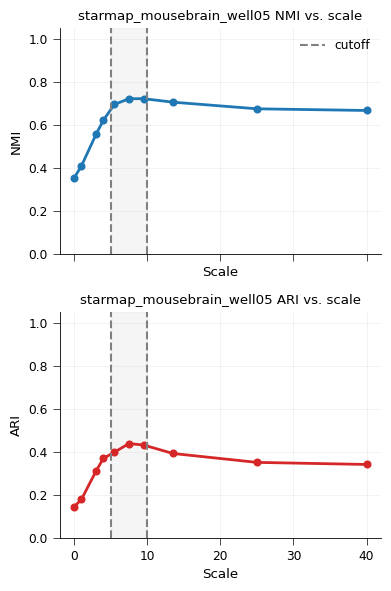

In [7]:
dataset_name = 'starmap_mousebrain_well05'
well05_target_n = custom_target_n_map[dataset_name]
well05_pred = load_predictions(dataset_name, 'spatialzoomer')
well05_true_labels, well05_pred = align_and_filter(dataset_name, well05_pred)
well05_scale_meta = parse_spatialzoomer_columns(well05_pred)
if well05_scale_meta.empty:
    raise ValueError(f'No SpatialZoomer columns were found for {dataset_name}.')

well05_scale_rows = []
for scale, group in well05_scale_meta.groupby('scale', sort=True):
    chosen = group.iloc[(group['n_clusters'] - well05_target_n).abs().argmin()]
    column_name = chosen['column']
    labels_pred = well05_pred[column_name].astype(str).values
    labels_true = well05_true_labels.values
    well05_scale_rows.append({
        'scale': float(scale),
        'column': column_name,
        'n_clusters': int(chosen['n_clusters']),
        'nmi': calculate_nmi(labels_pred, labels_true),
        'ari': calculate_ari(labels_pred, labels_true),
    })

well05_scale_summary = pd.DataFrame(well05_scale_rows).sort_values('scale')
if well05_scale_summary.empty:
    raise ValueError(f'No {dataset_name} scale metrics could be computed.')

fig, axes = plt.subplots(2, 1, figsize=(4, 6), sharex=True)
metric_specs = [
    ('nmi', 'NMI', '#1f77b4'),
    ('ari', 'ARI', '#d62728'),
]

for ax, (metric_col, metric_label, color) in zip(axes, metric_specs):
    ax.plot(
        well05_scale_summary['scale'],
        well05_scale_summary[metric_col],
        marker='o',
        linewidth=2,
        color=color,
    )
    ax.set_ylim(0, 1.05)
    ax.axvline(DEFAULT_SCALE_RANGE[0], linestyle='--', color='gray', linewidth=1.5, label='cutoff' )
    ax.axvline(DEFAULT_SCALE_RANGE[1], linestyle='--', color='gray', linewidth=1.5)
    ax.axvspan(DEFAULT_SCALE_RANGE[0], DEFAULT_SCALE_RANGE[1], color='gray', alpha=0.08)
    ax.set_title(f'{dataset_name} {metric_label} vs. scale')
    ax.set_xlabel('Scale')
    ax.set_ylabel(metric_label)
    ax.grid(True, alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(frameon=False, loc='best')
fig.tight_layout()
plt.show()


### 1.3 Plot Benchmark Results

In [8]:
# Load the results

brain_nmi = pd.read_csv('./Outputs/Brain_NMI.csv', index_col=0)
brain_ari = pd.read_csv('./Outputs/Brain_ARI.csv', index_col=0)
lung_nmi = pd.read_csv('./Outputs/Lung_NMI.csv', index_col=0)
lung_ari = pd.read_csv('./Outputs/Lung_ARI.csv', index_col=0)

C:\Users\lxq19\AppData\Local\Temp\ipykernel_40980\906540743.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(plot_order)
C:\Users\lxq19\AppData\Local\Temp\ipykernel_40980\906540743.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(plot_order)


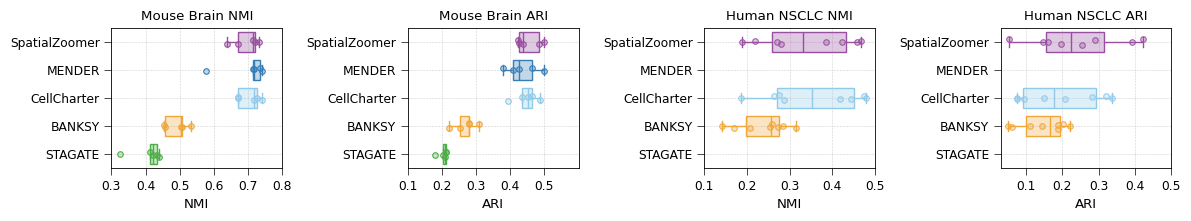

In [9]:
# Plot the ARI and NMI benchmark results

def rgba_from_hex(hex_color, alpha):
    r, g, b = mcolors.to_rgb(hex_color)
    return (r, g, b, alpha)


def draw_one_axis(ax, df, xlabel, fill_missing_zero=False):
    order = ["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"]

    if fill_missing_zero:
        plot_order = order
        df_plot = df.copy()
        for m in plot_order:
            sub = df_plot[df_plot['Method'] == m]
            if sub.empty or sub['Score'].isna().all():
                if sub.empty:
                    df_plot = pd.concat([df_plot, pd.DataFrame({"Method": [m], "Score": [0]})], ignore_index=True)
                else:
                    df_plot.loc[df_plot['Method'] == m, 'Score'] = 0
    else:
        df_plot = df.copy()
        plot_order = [m for m in order if m in df_plot['Method'].unique()]

    for label in plot_order:
        sub = df_plot[df_plot['Method'] == label]
        col_hex = color_map[label]
        sns.boxplot(
            data=sub, y='Method', x='Score', order=[label],
            width=0.7, showfliers=False, saturation=1, ax=ax,
            boxprops=dict(edgecolor=col_hex, facecolor=rgba_from_hex(col_hex, 0.30), linewidth=1.0),
            medianprops=dict(color=col_hex, linewidth=1.0),
            whiskerprops=dict(color=col_hex, linewidth=1.0),
            capprops=dict(color=col_hex, linewidth=1.0),
        )

    sns.stripplot(
        data=df_plot, y='Method', x='Score', order=plot_order,
        hue='Method', palette={k: color_map[k] for k in plot_order},
        dodge=False, legend=False, size=4, jitter=True, ax=ax
    )

    point_collections = ax.collections[-len(plot_order):]
    for coll, label in zip(point_collections, plot_order):
        col_hex = color_map[label]
        coll.set_facecolor(rgba_from_hex(col_hex, 0.30))
        if fill_missing_zero:
            coll.set_edgecolor(rgba_from_hex(col_hex, 0.90))
        else:
            coll.set_edgecolor(mcolors.to_rgb(col_hex))
        coll.set_linewidth(0.8)

    ax.set_xlabel(xlabel)
    ax.set_ylabel('')
    ax.grid(True, linestyle='--', alpha=0.6)

    xmin = np.nanmin(df['Score'])
    xmax = np.nanmax(df['Score'])
    ticks = np.arange(np.floor(xmin * 10) / 10, np.ceil(xmax * 10) / 10 + 0.05, 0.1)
    ax.set_xticks(ticks)

    if fill_missing_zero:
        ax.set_xlim(max(0.03, xmin - 0.0408), 0.5)
        ax.set_yticklabels(plot_order)


base_palette = ["#974F9F", "#377EB9",  "#91CAE8", "#F0A73A", "#4DAE48", "#4DAE48", "#C5D6C0"]
order = ["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"]
color_map = {name: col for name, col in zip(order, base_palette)}


fig, axes = plt.subplots(1, 4, figsize=(12, 2.3))

# Brain - NMI
melted_nmi_brain = brain_nmi.melt(var_name="Method", value_name="Score")
draw_one_axis(axes[0], melted_nmi_brain, "NMI", fill_missing_zero=False)
# axes[0].set_xlim(0.3, 0.8)
axes[0].set_title("Mouse Brain NMI")

# Brain - ARI
melted_ari_brain = brain_ari.melt(var_name="Method", value_name="Score")
draw_one_axis(axes[1], melted_ari_brain, "ARI", fill_missing_zero=False)
axes[1].set_xlim(0.1, 0.6)
axes[1].set_title("Mouse Brain ARI")

# Lung - NMI
melted_nmi_lung = lung_nmi.melt(var_name="Method", value_name="Score")
draw_one_axis(axes[2], melted_nmi_lung, "NMI", fill_missing_zero=True)
# axes[2].set_xlim(0.1, 0.5)
axes[2].set_title("Human NSCLC NMI")

# Lung - ARI
melted_ari_lung = lung_ari.melt(var_name="Method", value_name="Score")
draw_one_axis(axes[3], melted_ari_lung, "ARI", fill_missing_zero=True)
# axes[3].set_xlim(0, 0.5)
axes[3].set_title("Human NSCLC ARI")

plt.tight_layout()
plt.savefig( "./Outputs/ARI_NMI_plot.pdf", format="pdf", bbox_inches="tight")
plt.show()


## 2. Runtime and Memory Usage

This section compares runtime and peak memory usage across methods and datasets.

In [10]:
time_df = pd.read_csv('./Data/Figure6_benchmark_time_consumption.csv')
memory_df = pd.read_csv('./Data/Figure6_benchmark_peak_memory.csv')
time_df

,Datasets,Species,Sample type,Platform,Total cells,Total genes,SpatialZoomer,MENDER,CellCharter,BANKSY,STAGATE
0,cosmx_Lung12,Human,Lung,CosMx,71304,960,828.28,NaN,1799.92,420.14,NaN
1,cosmx_Lung13,Human,Lung,CosMx,81236,960,837.89,NaN,1788.60,452.99,NaN
2,cosmx_Lung5_Rep1,Human,Lung,CosMx,98002,960,1010.89,NaN,2208.75,561.26,NaN
3,cosmx_Lung5_Rep2,Human,Lung,CosMx,105800,960,1035.46,NaN,2296.79,637.96,NaN
4,cosmx_Lung5_Rep3,Human,Lung,CosMx,97809,960,973.74,NaN,2289.61,590.51,NaN
5,cosmx_Lung6,Human,Lung,CosMx,89975,960,871.38,NaN,2094.95,538.12,NaN
6,cosmx_Lung9_Rep1,Human,Lung,CosMx,87606,960,988.22,NaN,2009.60,513.60,NaN
7,cosmx_Lung9_Rep2,Human,Lung,CosMx,139504,960,990.50,NaN,2106.75,1580.02,NaN
8,cosmx_mousebrain,Mouse,Brain,CosMx,39494,960,685.24,167.01,1440.91,165.50,273.96
9,starmap_mousebrain_well05,Mouse,Brain,STARmap,46184,1022,688.15,188.27,1531.52,182.75,335.16


In [11]:
memory_df

,Datasets,Species,Sample type,Platform,Total cells,Total genes,SpatialZoomer,MENDER,CellCharter,BANKSY,STAGATE
0,cosmx_Lung12,Human,Lung,CosMx,71304,960,4320.83,NaN,1656.41,9541.26,NaN
1,cosmx_Lung13,Human,Lung,CosMx,81236,960,4779.45,NaN,1641.62,10636.24,NaN
2,cosmx_Lung5_Rep1,Human,Lung,CosMx,98002,960,5651.70,NaN,1688.53,12809.16,NaN
3,cosmx_Lung5_Rep2,Human,Lung,CosMx,105800,960,6098.39,NaN,1883.69,14005.69,NaN
4,cosmx_Lung5_Rep3,Human,Lung,CosMx,97809,960,5619.34,NaN,1657.12,12498.37,NaN
5,cosmx_Lung6,Human,Lung,CosMx,89975,960,5243.48,NaN,1913.43,11597.53,NaN
6,cosmx_Lung9_Rep1,Human,Lung,CosMx,87606,960,5110.27,NaN,1681.75,11406.17,NaN
7,cosmx_Lung9_Rep2,Human,Lung,CosMx,139504,960,7685.43,NaN,1967.60,18044.13,NaN
8,cosmx_mousebrain,Mouse,Brain,CosMx,39494,960,3886.79,19040.23,1638.23,5573.71,1835.16
9,starmap_mousebrain_well05,Mouse,Brain,STARmap,46184,1022,3679.92,25656.36,1569.49,6605.53,2150.91


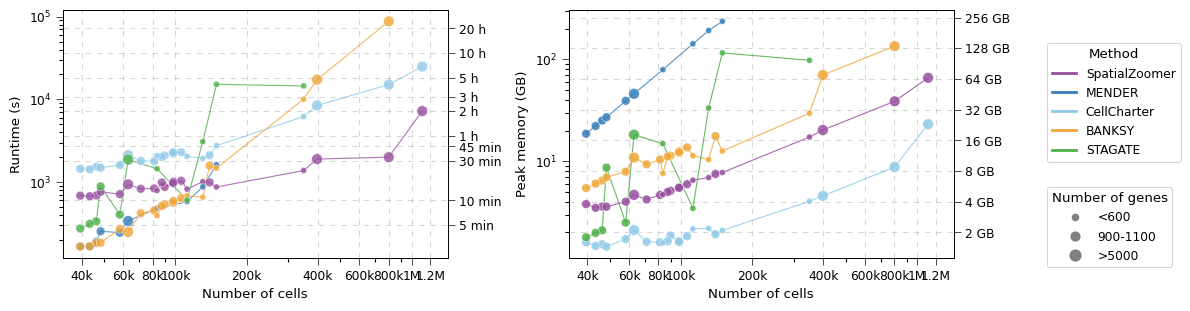

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FixedLocator, FuncFormatter
from matplotlib.lines import Line2D

order = ["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"]
base_palette = ["#974F9F", "#377EB9",  "#91CAE8", "#F0A73A", "#4DAE48", "#4DAE48", "#C5D6C0"]
palette_map = dict(zip(["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"], base_palette))

def gene_group(g):
    if pd.isna(g):
        return np.nan
    if g < 600:
        return "<600"
    if 900 < g < 1100:
        return "900-1100"
    if g > 5000:
        return ">5000"
    return ""

time_df["GeneGroup"] = time_df["Total genes"].apply(gene_group)
memory_df["GeneGroup"] = memory_df["Total genes"].apply(gene_group)

# Time
df_time = time_df.melt(
    id_vars=["Total cells", "GeneGroup"],
    value_vars=["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"],
    var_name='Method',
    value_name='Time_seconds'
).dropna(subset=["Time_seconds"])

# Memory
df_mem = memory_df.melt(
    id_vars=["Total cells", "GeneGroup"],
    value_vars=["SpatialZoomer", "MENDER", "CellCharter", "BANKSY", "STAGATE"],
    var_name='Method',
    value_name='Memory_MB'
).dropna(subset=["Memory_MB"])
df_mem["Memory_GB"] = df_mem["Memory_MB"] / 1024.0

for _df in (df_time, df_mem):
    _df["Method"] = pd.Categorical(_df["Method"], categories=order, ordered=True)


size_map = {"<600": 20, "900-1100": 40, ">5000": 60}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.2), sharex=True)


# ===== Left：Time =====
sns.lineplot(
    data=df_time, x='Total cells', y='Time_seconds', hue='Method',hue_order=order,
    palette=palette_map, marker=None, alpha=0.8, ax=ax1, legend=False
)
sns.scatterplot(
    data=df_time, x='Total cells', y='Time_seconds', hue='Method',hue_order=order,
    palette=palette_map, size='GeneGroup', sizes=size_map, legend=False,
    ax=ax1, alpha=0.8, zorder=3
)
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_xlabel("Number of cells")
ax1.set_ylabel("Runtime (s)")
xticks = [40000, 60000, 80000, 100000, 200000, 400000, 600000, 800000, 1000000, 1200000]
ax1.set_xticks(xticks)
ax1.set_xticklabels(['40k', '60k', '80k', '100k', '200k', '400k', '600k', '800k', '1M', '1.2M'])

# mins/hours
ax1_r = ax1.twinx()
ax1_r.set_yscale("log")
ax1_r.set_ylim(ax1.get_ylim())
right_ticks_sec = [300, 600, 1800, 2700, 3600, 7200, 10800, 18000, 36000, 72000]
ax1_r.yaxis.set_major_locator(FixedLocator(right_ticks_sec))
def seconds_to_min_label(x, pos):
    if x < 60: return f"{int(x)} s"
    elif x < 3600: return f"{int(x/60)} min"
    else: return f"{int(x/3600)} h"
ax1_r.yaxis.set_major_formatter(FuncFormatter(seconds_to_min_label))
ax1_r.yaxis.set_minor_locator(FixedLocator([]))
ax1_r.set_ylabel("", labelpad=15)

ax1.grid(False); ax1_r.grid(False)
for xv in xticks:
    ax1.axvline(x=xv, color='gray', linestyle=(0, (5, 5)), linewidth=0.8, alpha=0.3)
for y in right_ticks_sec:
    if ax1.get_ylim()[0] <= y <= ax1.get_ylim()[1]:
        ax1.axhline(y=y, color='gray', linestyle=(0, (5, 5)), linewidth=0.8, alpha=0.3)


# ===== Right：Memory =====
sns.lineplot(
    data=df_mem, x='Total cells', y='Memory_GB', hue='Method',hue_order=order,
    palette=palette_map, marker=None, alpha=0.85, ax=ax2, legend=False
)
sns.scatterplot(
    data=df_mem, x='Total cells', y='Memory_GB', hue='Method',hue_order=order,
    palette=palette_map, size='GeneGroup', sizes=size_map, legend=False,
    alpha=0.85, ax=ax2, zorder=3
)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel("Number of cells")
ax2.set_ylabel("Peak memory (GB)")
ax2.set_xticks(xticks)
ax2.set_xticklabels(['40k', '60k', '80k', '100k', '200k', '400k', '600k', '800k', '1M', '1.2M'])

# GB
ax2_r = ax2.twinx()
ax2_r.set_yscale('log')
gb_ticks = np.array([2, 4, 8, 16, 32, 64, 128, 256], dtype=float)
ymin, ymax = ax2.get_ylim()
ax2.set_ylim(min(ymin, gb_ticks.min()), max(ymax, gb_ticks.max()))
ax2_r.set_ylim(ax2.get_ylim())
ax2_r.set_yticks(gb_ticks)
ax2_r.set_yticklabels([f"{int(v)} GB" for v in gb_ticks])
ax2_r.grid(False)
ax2_r.yaxis.set_minor_locator(FixedLocator([])) 

ax2.grid(False)
for xv in xticks:
    ax2.axvline(x=xv, color='gray', linestyle=(0, (5, 5)), linewidth=0.8, alpha=0.3)
for y in gb_ticks:
    ax2.axhline(y=y, color='gray', linestyle=(0, (5, 5)), linewidth=0.8, alpha=0.3)

# ===== legend =====
from matplotlib.lines import Line2D

method_order = order
method_handles = [
    Line2D([0], [0], color=palette_map[m], lw=2, label=m) for m in method_order
]

fig.legend(
    handles=method_handles,
    title="Method",
    loc="upper left",
    bbox_to_anchor=(1.001, 0.85),
    borderaxespad=0
)

size_handles = [
    Line2D([0], [0], marker='o', color='gray', markerfacecolor='gray',
           markersize=np.sqrt(size_map["<600"]), linestyle='None', label='<600'),
    Line2D([0], [0], marker='o', color='gray', markerfacecolor='gray',
           markersize=np.sqrt(size_map["900-1100"]), linestyle='None', label='900-1100'),
    Line2D([0], [0], marker='o', color='gray', markerfacecolor='gray',
           markersize=np.sqrt(size_map[">5000"]), linestyle='None', label='>5000'),
]
fig.legend(
    handles=size_handles,
    title="Number of genes",
    loc="lower left",
    bbox_to_anchor=(1.001, 0.15),
    borderaxespad=0
)

plt.tight_layout(rect=[0, 0, 0.98, 1])
plt.savefig("./Outputs/Time_memory_plot.pdf", format="pdf", bbox_inches='tight')  
plt.show()
